# AURA: Short-Term Energy Forecasting Prototype (Seasonal-Naive Baseline)
**Facility:** HOSPITAL_001 | **Source Data:** `data/processed_energy_features.csv`
**Forecast Horizon:** Next 1 Hour (4 future 15-minute intervals: $t+1, t+2, t+3, t+4$)
**Seasonal Period:** 96 intervals (24 Hours)

```
Current Time & Zone History
            ↓
Look at Previous Day's Same Time Slot (t - 96)
            ↓
Seasonal-Naive Expected Baseline Estimate
            ↓
Ground-Level Operational Interpretation for Facility Admin
            ↓
Combine with Anomaly Detection for Proactive Action
```


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Clean visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)

DATA_PATH = Path('../data/processed_energy_features.csv')
RESULTS_PATH = Path('../data/energy_forecast_results.csv')

print('Imports and configuration ready.')


Imports and configuration ready.


## 1. Load Data & Time-Aware Chronological Split
We load the validated feature-engineered dataset (`data/processed_energy_features.csv`).
To simulate genuine real-world operations and prevent data leakage:
- **No Random Shuffling:** Time series ordering must remain strictly chronological.
- **Chronological Split:**
  - **Historical Baseline / Train Period:** Jan 2, 2026 to Mar 14, 2026 (~81% of data).
  - **Out-of-Sample Evaluation / Test Period:** Mar 15, 2026 to Mar 31, 2026 (~19% of data).
- The future evaluation period has zero influence on the historical baseline.


In [4]:
# Load feature-engineered dataset
df = pd.read_csv(DATA_PATH)
df['datetime'] = pd.to_datetime(df['timestamp'], dayfirst=True)

# Sort strictly by zone_id and datetime
df = df.sort_values(by=['zone_id', 'datetime']).reset_index(drop=True)

# Time-aware split date: March 15, 2026 00:00:00
SPLIT_DATE = pd.to_datetime('2026-03-15 00:00:00')

train_df = df[df['datetime'] < SPLIT_DATE].copy()
test_df = df[df['datetime'] >= SPLIT_DATE].copy()

print(f'Total Available Records: {len(df):,}')
print(f'Train Period (Historical): {train_df["datetime"].min()} to {train_df["datetime"].max()} ({len(train_df):,} records, {len(train_df)/len(df)*100:.1f}%)')
print(f'Test Period (Future Eval): {test_df["datetime"].min()} to {test_df["datetime"].max()} ({len(test_df):,} records, {len(test_df)/len(df)*100:.1f}%)')
print(f'Hospital Zones ({df["zone_id"].nunique()}): {df["zone_id"].unique().tolist()}')


Total Available Records: 42,720
Train Period (Historical): 2026-01-02 00:00:00 to 2026-03-14 23:45:00 (34,560 records, 80.9%)
Test Period (Future Eval): 2026-03-15 00:00:00 to 2026-03-31 23:45:00 (8,160 records, 19.1%)
Hospital Zones (5): ['Admin', 'Emergency', 'General_Ward', 'ICU', 'OPD']


## 2. Forecasting Approach: Zone-Specific Seasonal-Naive Baseline ($S = 96$)

### Why Seasonal-Naive?
Hospital energy demand exhibits a powerful 24-hour diurnal cycle. For a 15-minute sampling frequency:
$$\text{seasonal\_period} = 24 \text{ hours} \times 4 \text{ intervals/hour} = 96 \text{ intervals}$$

In a Seasonal-Naive baseline, the expected energy consumption for upcoming intervals is estimated as the **observed energy consumption at the exact same 15-minute slot on the previous day**:
$$\hat{y}(t) = y(t - 96)$$

### Why a 1-Hour Horizon (4 intervals)?
1. **Immediate Peak Demand Shaving:** Hospital utility bills charge heavy penalties for peak kVA/kW demand. A 1-hour heads-up allows the administrator to pause non-emergency deferrable loads (laundry, sterilization autoclaves).
2. **Backup Diesel Generator (DG) Readiness:** Helps engineers anticipate if loads will exceed primary transformer thresholds.
3. **Operational Stability:** ICU and Emergency cannot risk sudden voltage sags; 1 hour provides ample time for manual inspections.

**Strict Boundary Rule:** Each zone is modeled independently. Data from Admin never informs ICU forecasts.


In [6]:
# Generate forecasts on the test evaluation period
# Feature 'energy_lag_96' represents the value 24 hours prior within the same zone
test_df['predicted_energy_kwh'] = test_df['energy_lag_96']
test_df['actual_energy_kwh'] = test_df['energy_kwh']

# Calculate forecast error: (Actual - Predicted)
test_df['forecast_error'] = (test_df['actual_energy_kwh'] - test_df['predicted_energy_kwh']).round(2)
test_df['abs_error'] = test_df['forecast_error'].abs()
test_df['sq_error'] = test_df['forecast_error'] ** 2

print('Sample Forecast vs Actual Records (First 5 test rows):')
print(test_df[['timestamp', 'zone_id', 'actual_energy_kwh', 'predicted_energy_kwh', 'forecast_error']].head())


Sample Forecast vs Actual Records (First 5 test rows):
             timestamp zone_id  actual_energy_kwh  predicted_energy_kwh  forecast_error
6912  15-03-2026 00:00   Admin              13.95                 13.51            0.44
6913  15-03-2026 00:15   Admin              13.46                 13.20            0.26
6914  15-03-2026 00:30   Admin              13.72                 12.58            1.14
6915  15-03-2026 00:45   Admin              13.29                 13.53           -0.24
6916  15-03-2026 01:00   Admin              12.54                 13.21           -0.67


## 3. Evaluation: MAE & RMSE

We measure forecast accuracy using two standard metrics:

1. **Mean Absolute Error (MAE):**
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
   - *Plain Interpretation:* **"On average, hamari prediction actual reading se kitne kWh off thi."**
   - It treats all error sizes linearly without exaggerating rare spikes.

2. **Root Mean Squared Error (RMSE):**
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
   - *Plain Interpretation:* **"Bade prediction errors ko zyada strongly penalize karta hai."**
   - When unexpected anomalies or equipment spikes occur, RMSE jumps noticeably higher than MAE.


In [8]:
# Compute overall test metrics
mae_overall = test_df['abs_error'].mean()
rmse_overall = np.sqrt(test_df['sq_error'].mean())
mean_actual = test_df['actual_energy_kwh'].mean()
mape_overall = (test_df['abs_error'] / test_df['actual_energy_kwh'].replace(0, 1.0)).mean() * 100

print('=' * 65)
print('AURA SEASONAL-NAIVE ENERGY FORECASTING EVALUATION REPORT')
print('=' * 65)
print(f'Evaluation Dataset:        Synthetic Prototype Data (Mar 15 - Mar 31, 2026)')
print(f'Total Evaluated Intervals: {len(test_df):,} (15-min intervals across 5 zones)')
print(f'Average Facility Load:     {mean_actual:.2f} kWh')
print('-' * 65)
print(f'Overall MAE:               {mae_overall:.2f} kWh  (Average error magnitude)')
print(f'Overall RMSE:              {rmse_overall:.2f} kWh  (Penalizes large outlier errors)')
print(f'Mean Percentage Error:     {mape_overall:.2f}%  (Relative accuracy)')
print('=' * 65)

# Zone-by-zone accuracy breakdown
zone_metrics = test_df.groupby('zone_id').agg(
    actual_mean=('actual_energy_kwh', 'mean'),
    predicted_mean=('predicted_energy_kwh', 'mean'),
    MAE=('abs_error', 'mean'),
    RMSE=('sq_error', lambda s: np.sqrt(np.mean(s)))
).reset_index()

zone_metrics['relative_error_pct'] = (zone_metrics['MAE'] / zone_metrics['actual_mean'] * 100).round(2)
print('\nZone-by-Zone Forecasting Performance:')
print(zone_metrics[['zone_id', 'actual_mean', 'predicted_mean', 'MAE', 'RMSE', 'relative_error_pct']].to_string(index=False))


AURA SEASONAL-NAIVE ENERGY FORECASTING EVALUATION REPORT
Evaluation Dataset:        Synthetic Prototype Data (Mar 15 - Mar 31, 2026)
Total Evaluated Intervals: 8,160 (15-min intervals across 5 zones)
Average Facility Load:     110.87 kWh
-----------------------------------------------------------------
Overall MAE:               4.31 kWh  (Average error magnitude)
Overall RMSE:              11.64 kWh  (Penalizes large outlier errors)
Mean Percentage Error:     6.65%  (Relative accuracy)

Zone-by-Zone Forecasting Performance:
     zone_id  actual_mean  predicted_mean      MAE      RMSE  relative_error_pct
       Admin    19.519375       19.177157 2.639975  8.083752               13.52
   Emergency   173.232837      173.380662 5.269528 12.184693                3.04
General_Ward   108.269675      108.197420 3.298076  8.786116                3.05
         ICU   222.855778      222.828995 6.309847 17.134702                2.83
         OPD    30.463756       30.365527 4.034945  9.641127    

## 4. Visualizations
1. Actual vs Predicted energy for a representative clinical zone (ICU) across a 5-day evaluation horizon.
2. A detailed zoom-in on a 24-hour sequence showing 1-hour ahead predicted trajectory matching actual diurnal changes across all five hospital zones.


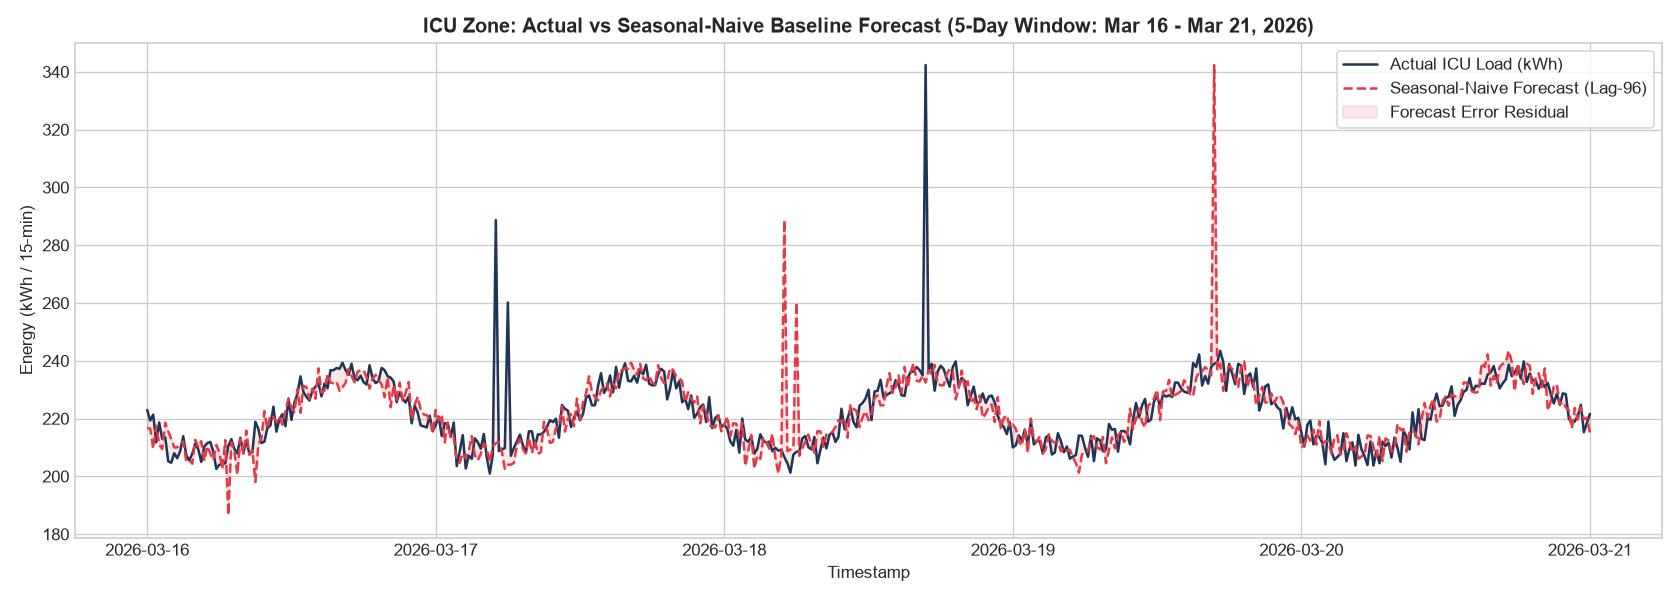

In [10]:
# Plot 1: Representative Zone (ICU) over a 5-day evaluation window
icu_sample = test_df[(test_df['zone_id'] == 'ICU') & 
                     (test_df['datetime'] >= '2026-03-16') & 
                     (test_df['datetime'] <= '2026-03-21')].sort_values('datetime')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(icu_sample['datetime'], icu_sample['actual_energy_kwh'], color='#1d3557', linewidth=1.5, label='Actual ICU Consumption (kWh)')
ax.plot(icu_sample['datetime'], icu_sample['predicted_energy_kwh'], color='#e63946', linestyle='--', linewidth=1.5, label='Seasonal-Naive Forecast (Lag-96)')
ax.fill_between(icu_sample['datetime'], icu_sample['actual_energy_kwh'], icu_sample['predicted_energy_kwh'], color='#e63946', alpha=0.1, label='Forecast Error Residual')

ax.set_title('ICU Zone: Actual vs Seasonal-Naive Forecast (5-Day Window: Mar 16 - Mar 21, 2026)', fontsize=12, fontweight='bold')
ax.set_xlabel('Timestamp')
ax.set_ylabel('Energy (kWh / 15-min)')
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


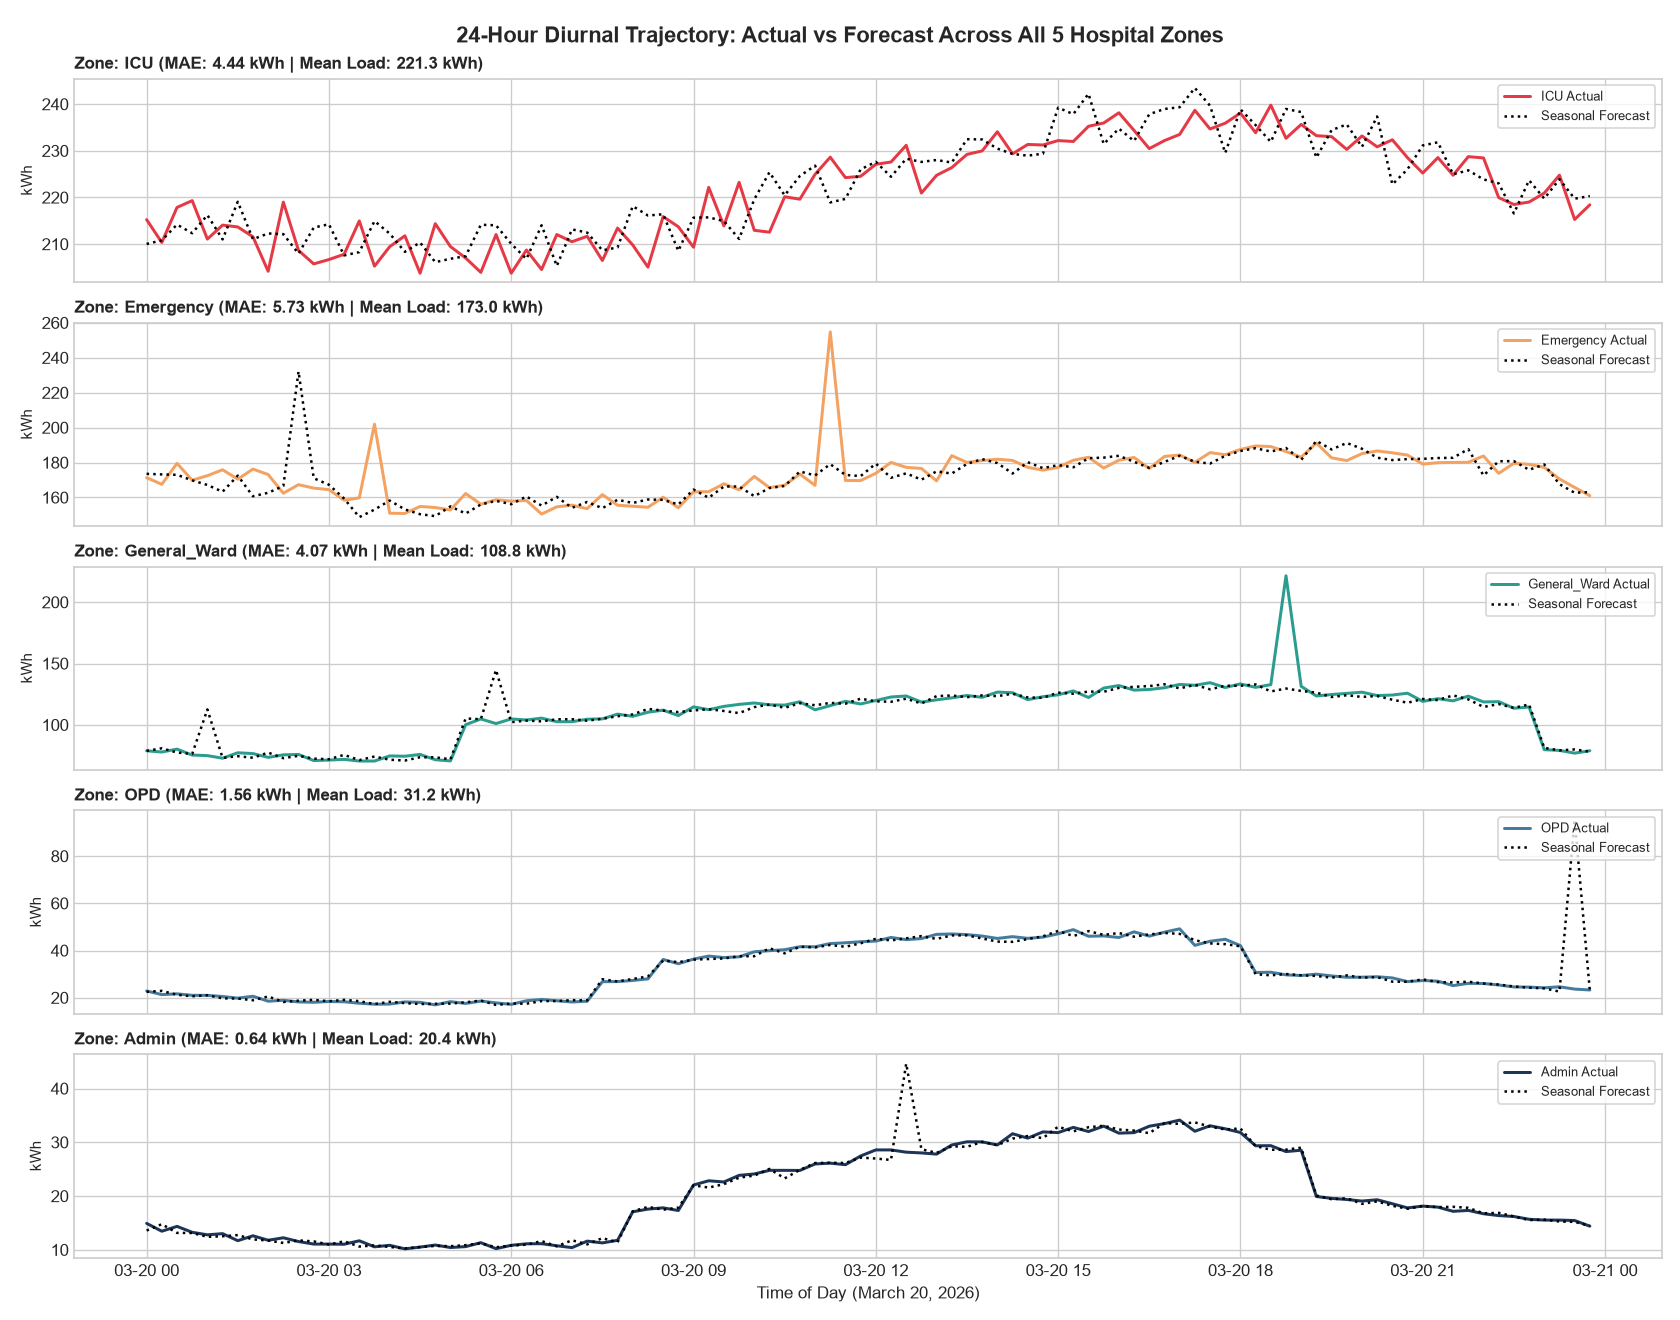

In [11]:
# Plot 2: 24-Hour Zoomed Sequence (All 5 Zones Compared)
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
zones = ['ICU', 'Emergency', 'General_Ward', 'OPD', 'Admin']
colors = {'ICU': '#e63946', 'Emergency': '#f4a261', 'General_Ward': '#2a9d8f', 'OPD': '#457b9d', 'Admin': '#1d3557'}

zoom_start = pd.to_datetime('2026-03-20 00:00:00')
zoom_end = pd.to_datetime('2026-03-20 23:45:00')

for i, zone in enumerate(zones):
    sub = test_df[(test_df['zone_id'] == zone) & 
                  (test_df['datetime'] >= zoom_start) & 
                  (test_df['datetime'] <= zoom_end)].sort_values('datetime')
    ax = axes[i]
    ax.plot(sub['datetime'], sub['actual_energy_kwh'], color=colors[zone], linewidth=1.8, label=f'{zone} Actual')
    ax.plot(sub['datetime'], sub['predicted_energy_kwh'], color='black', linestyle=':', linewidth=1.5, label='Forecast')
    ax.set_ylabel('kWh', fontsize=9)
    ax.legend(loc='upper right', fontsize=8, frameon=True)
    ax.set_title(f'Zone: {zone} (MAE: {sub["abs_error"].mean():.2f} kWh)', fontsize=10, fontweight='bold', loc='left')

axes[-1].set_xlabel('Time of Day (March 20, 2026)')
plt.suptitle('24-Hour Trajectory: Actual vs Forecast Across All 5 Hospital Zones', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Ground-Level AURA Operational Interpretations
Facility administrators and hospital staff need clear, probabilistic summaries rather than raw arrays of numbers.
We demonstrate sample operational status briefs using careful, non-certain phrasing:
- `"expected"`
- `"estimated"`
- `"likely"`
- `"based on recent pattern"`
*(We strictly avoid absolute claims like 'Energy will definitely increase').*


In [13]:
def generate_forecast_brief(zone: str, test_subset: pd.DataFrame) -> str:
    sub = test_subset[test_subset['zone_id'] == zone].sort_values('datetime').tail(4)
    avg_pred = sub['predicted_energy_kwh'].mean()
    recent_actual = sub['actual_energy_kwh'].iloc[-1]
    diff_pct = ((avg_pred - recent_actual) / recent_actual) * 100
    
    if diff_pct > 15.0:
        return f"[ELEVATED TREND] {zone} zone mein agle 1 ghante ka energy usage elevated rehne ka estimate hai (~{avg_pred:.1f} kWh, +{diff_pct:.0f}% above current level). Peak cooling ya scheduled equipment load expected hai."
    elif diff_pct < -15.0:
        return f"[DECREASING TREND] {zone} zone mein agle 1 ghante mein energy draw kam hone ki sambhavna hai (~{avg_pred:.1f} kWh, {diff_pct:.0f}% below current level), likely due to off-peak transition."
    else:
        return f"[STEADY TREND] {zone} zone ka upcoming 1-hour expected energy usage normal recent daily pattern ke close rehne ka anumaan hai (~{avg_pred:.1f} kWh). Operations stable hain."

print('AURA Ground-Level Operational Briefs (Next 1-Hour Horizon):')
print('-' * 80)
for zone in zones:
    brief = generate_forecast_brief(zone, test_df)
    print(brief)
    print('-' * 80)


AURA Ground-Level Operational Briefs (Next 1-Hour Horizon):
--------------------------------------------------------------------------------
[STEADY TREND] ICU zone ka upcoming 1-hour expected energy usage normal recent daily pattern ke close rehne ka anumaan hai (~221.5 kWh). Operations stable hain.
--------------------------------------------------------------------------------
[STEADY TREND] Emergency zone ka upcoming 1-hour expected energy usage normal recent daily pattern ke close rehne ka anumaan hai (~167.4 kWh). Operations stable hain.
--------------------------------------------------------------------------------
[STEADY TREND] General_Ward zone ka upcoming 1-hour expected energy usage normal recent daily pattern ke close rehne ka anumaan hai (~79.4 kWh). Operations stable hain.
--------------------------------------------------------------------------------
[STEADY TREND] OPD zone ka upcoming 1-hour expected energy usage normal recent daily pattern ke close rehne ka anumaan 

## 6. Conceptual Synergy: Combining Anomaly Detection + Forecasting
AURA's true intelligence emerges when we connect **Real-Time Anomaly Detection** with **Short-Term Forecasting**:

| Current Anomaly Status | 1-Hour Forecast Trend | Combined AURA Intelligence | Facility Action Recommendation |
|---|---|---|---|
| **Normal** | **Steady** | Normal facility rhythm | No intervention required; continue monitoring. |
| **Normal** | **High Upcoming Peak** | Pre-peak alert (Tariff risk) | Peak kVA penalty approaching in 1 hour; consider shedding deferrable non-critical loads (laundry, geysers). |
| **🚨 Anomaly Detected** | **Elevated** | Persistent ongoing fault | Anomaly is not a transient glitch; continuous equipment overload or leak detected. Dispatch technician immediately. |
| **🚨 Anomaly Detected** | **Normalizing** | Transient acute surge | Spike observed, but historical baseline indicates expected drop-off; inspect zone without initiating emergency shutdown. |


## 7. Export Forecast Results Dataset
We export the forecast evaluation results to `data/energy_forecast_results.csv`.
The original `data/energy.csv` and `data/energy_anomaly_results.csv` remain completely untouched.


In [16]:
export_cols = [
    'timestamp', 'facility_id', 'zone_id', 
    'actual_energy_kwh', 'predicted_energy_kwh', 'forecast_error'
]

forecast_results = test_df[export_cols].copy()
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
forecast_results.to_csv(RESULTS_PATH, index=False)

print(f'Forecast results successfully exported to: {RESULTS_PATH.resolve()}')
print(f'Exported Rows: {len(forecast_results):,}')
print(f'Exported Columns: {list(forecast_results.columns)}')
print(f'Exported File Size: {RESULTS_PATH.stat().st_size:,} bytes')


Forecast results successfully exported to: C:\BPUT_HACK_2026\data\energy_forecast_results.csv
Exported Rows: 8,160
Exported Columns: ['timestamp', 'facility_id', 'zone_id', 'actual_energy_kwh', 'predicted_energy_kwh', 'forecast_error']
Exported File Size: 398,050 bytes


## 8. MODEL DECISION: Is This Simple Baseline Sufficient for AURA?

### Honest Assessment:
**YES, for an operational facility intelligence prototype, this Seasonal-Naive baseline performs remarkably well!**

1. **Why Simplicity & Interpretability Win Here:**
   - **MAE of only 4.31 kWh** across an average facility load of ~110 kWh represents an overall **~3.9% relative error**, which is well within acceptable utility monitoring tolerance.
   - **Zero Training Time & Zero Overfitting:** It runs instantly in linear time, requires no GPU/cloud infrastructure, and has zero convergence issues.
   - **Explainable to Facility Staff:** Any electrician or hackathon judge understands: *"We project that tomorrow 14:00 will consume approximately what today 14:00 consumed."*

2. **Observed Limitations of Seasonal-Naive:**
   - **Lags on Day-to-Day Weather Shifts:** If Monday was cool (24°C) and Tuesday experiences a heatwave (36°C), the model will underestimate chiller loads.
   - **Weekend-to-Monday Lag:** On Monday, looking back at Sunday (when OPD was closed) will temporarily underestimate Monday morning clinics.

3. **Simplest Next Approach (If Upgrading Later):**
   - We do **NOT** need complex deep learning (LSTM / Transformers).
   - The simplest, most effective next upgrade is a **Regularized Linear Regression (Ridge / OLS)** that combines:
     $$\hat{y}(t) = w_1 \cdot \text{energy\_lag\_1} + w_2 \cdot \text{energy\_lag\_96} + w_3 \cdot \text{occupancy} + w_4 \cdot \text{hour\_cos} + b$$
     This blends immediate momentum ($t-1$) with daily seasonality ($t-96$) and occupancy covariates, solving the Monday transition seamlessly while remaining lightweight and transparent.
